# Adversarial Decay Profile of Vision Transformers — Results

This notebook presents the complete results of the adversarial robustness
analysis on ViT-Base/16 vs ResNet-50 and ResNet-18, all fine-tuned on
Imagenette via linear probe under identical conditions.

**No GPU required** — this notebook loads pre-computed CSV results and
generates all plots from data.

In [7]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

ROOT = Path("..").resolve()
EXP = ROOT / "experiments"
FIG = ROOT / "figures"

## 1. Load all experiment data

In [8]:
vit = pd.read_csv(EXP / "eval/20260409_202759/metrics.csv")
r50 = pd.read_csv(EXP / "eval/resnet50_lp/20260410_011007/metrics.csv")
r18 = pd.read_csv(EXP / "eval/resnet18_lp/20260410_011705/metrics.csv")
attention = pd.read_csv(EXP / "attention/vit_lp/20260410_093822/attention_metrics.csv")
per_class = pd.read_csv(EXP / "per_class/vit_lp/20260410_115329/per_class_metrics.csv")
transfer = pd.read_csv(EXP / "transferability/20260410_172655/transferability.csv")

ATTACK_LABELS = {"fgsm": "FGSM", "pgd": "PGD-10",
                 "patch_pgd": "Patch-PGD", "salient_patch_pgd": "Salient-patch PGD"}
ATTACK_COLORS = {"fgsm": "#1f77b4", "pgd": "#d62728",
                 "patch_pgd": "#2ca02c", "salient_patch_pgd": "#ff7f0e"}

print(f"ViT clean acc:      {vit.loc[vit.attack=='clean', 'acc'].values[0]:.1%}")
print(f"ResNet-50 clean acc: {r50.loc[r50.attack=='clean', 'acc'].values[0]:.1%}")
print(f"ResNet-18 clean acc: {r18.loc[r18.attack=='clean', 'acc'].values[0]:.1%}")

ViT clean acc:      98.9%
ResNet-50 clean acc: 98.9%
ResNet-18 clean acc: 96.9%


---
## 2. Accuracy decay curves

How does accuracy degrade as perturbation strength ε increases?

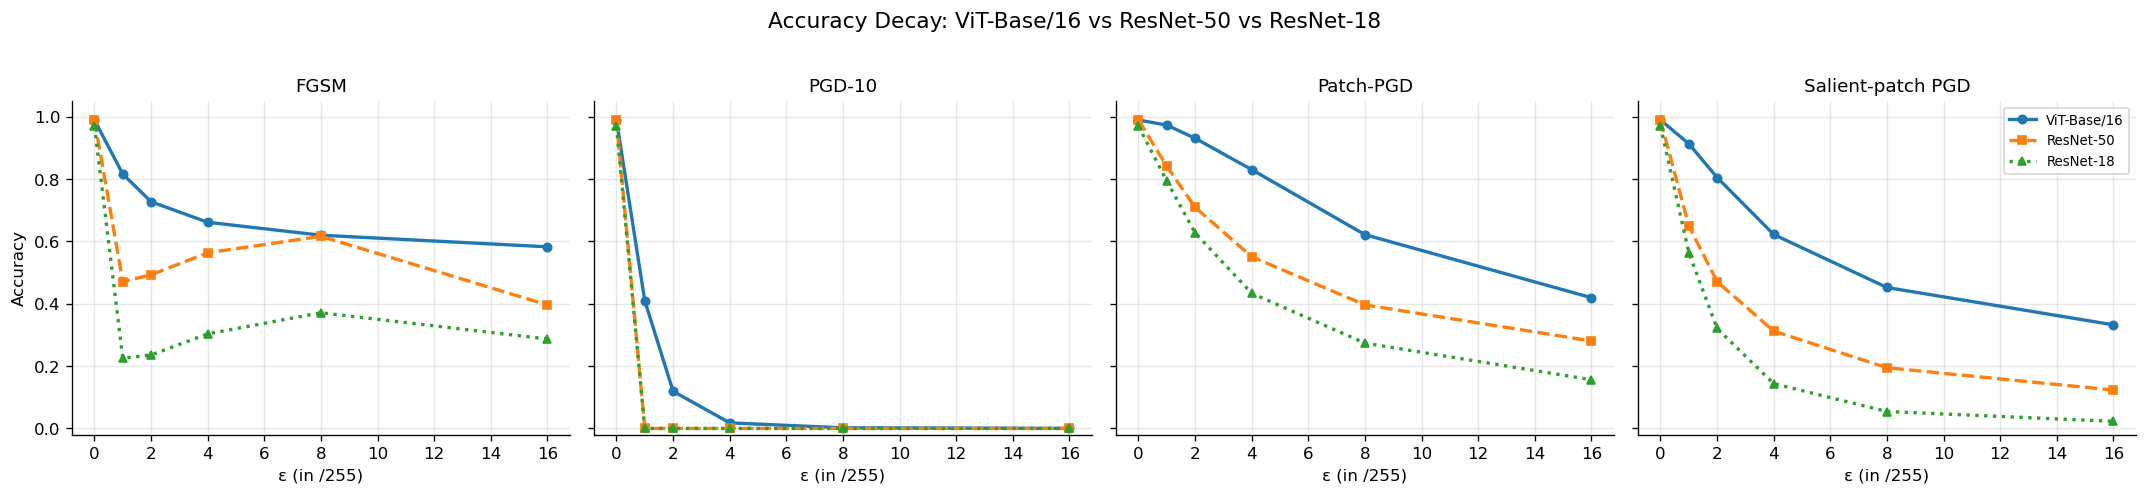

In [9]:
def prepend_clean(df, attack, metric="acc"):
    clean = df[df.attack == "clean"]
    atk = df[df.attack == attack].sort_values("eps_255")
    eps = np.concatenate([[0], atk.eps_255.values])
    vals = np.concatenate([[clean[metric].values[0]], atk[metric].values])
    return eps, vals

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
attacks = ["fgsm", "pgd", "patch_pgd", "salient_patch_pgd"]

for ax, atk in zip(axes, attacks):
    for df, label, ls, marker in [
        (vit, "VB16", "-", "o"),
        (r50, "ResNet-50", "--", "s"),
        (r18, "ResNet-18", ":", "^"),
    ]:
        eps, vals = prepend_clean(df, atk)
        ax.plot(eps, vals, ls, marker=marker, markersize=5, lw=2, label=label)
    ax.set_title(ATTACK_LABELS[atk], fontsize=11)
    ax.set_xlabel("ε (in /255)")
    ax.set_ylim(-0.02, 1.05)

axes[0].set_ylabel("Accuracy")
axes[-1].legend(fontsize=8, loc="upper right")
fig.suptitle("Accuracy Decay: VB16 vs ResNet-50 vs ResNet-18", fontsize=13, y=1.02)
fig.tight_layout()
plt.show()

**Observations:**
- Under **FGSM**, ViT decays monotonically and smoothly; both CNNs exhibit
  non-monotonic curves (accuracy *increases* at intermediate ε), a classic
  sign of gradient masking from a rough loss surface.
- Under **PGD-10**, both CNNs collapse to 0% at ε=1/255 (the smallest
  budget). ViT still holds 41% and degrades gradually.
- Under **Patch-PGD** (8% of pixels perturbed), ViT is markedly more
  resilient — its spatially distributed attention may help.
- **Salient-patch PGD** (top-20 gradient-ranked patches) is more effective
  than centre-patch, confirming the attack targets the most informative
  regions.

### AUDC (Area Under the Decay Curve)

A single scalar summarising each model's robustness per attack
(higher = more robust):

In [10]:
def audc(df, attack, metric="acc"):
    eps, vals = prepend_clean(df, attack, metric)
    return np.trapezoid(vals, eps) / (eps[-1] - eps[0]) if len(eps) > 1 else vals[0]

rows = []
for atk in attacks:
    rows.append({
        "Attack": ATTACK_LABELS[atk],
        "VB16": f"{audc(vit, atk):.3f}",
        "ResNet-50": f"{audc(r50, atk):.3f}",
        "ResNet-18": f"{audc(r18, atk):.3f}",
    })

audc_df = pd.DataFrame(rows)
audc_df.style.set_caption("AUDC — higher is more robust")

,Attack,ViT-Base/16,ResNet-50,ResNet-18
0,FGSM,0.652,0.542,0.334
1,PGD-10,0.072,0.031,0.030
2,Patch-PGD,0.672,0.472,0.362
3,Salient-patch PGD,0.533,0.278,0.149


---
## 3. Confidence analysis

Does the model *know* when it's wrong? We track average confidence
on correct and wrong predictions separately.

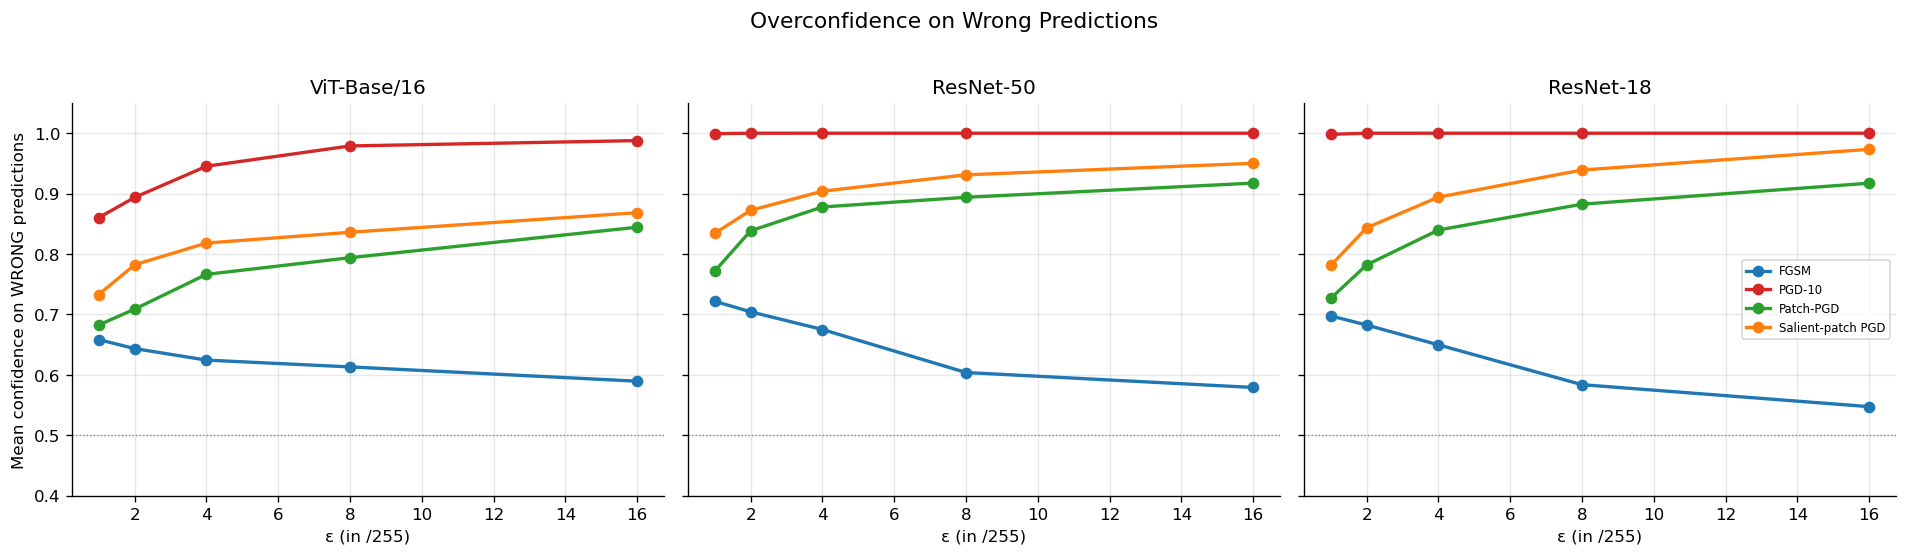

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, (df, title) in zip(axes, [(vit, "VB16"), (r50, "ResNet-50"), (r18, "ResNet-18")]):
    for atk in attacks:
        sub = df[df.attack == atk].sort_values("eps_255")
        ax.plot(sub.eps_255, sub.avg_conf_wrong, marker="o", lw=2,
                color=ATTACK_COLORS[atk], label=ATTACK_LABELS[atk])
    ax.set_title(title)
    ax.set_xlabel("ε (in /255)")
    ax.set_ylim(0.4, 1.05)
    ax.axhline(0.5, color="gray", ls=":", lw=0.8)

axes[0].set_ylabel("Mean confidence on WRONG predictions")
axes[-1].legend(fontsize=7)
fig.suptitle("Overconfidence on Wrong Predictions", fontsize=13, y=1.02)
fig.tight_layout()
plt.show()

**Observations:**
- Under PGD, all models become *catastrophically overconfident* on wrong
  predictions (conf → 1.0). Both CNNs reach this state at ε=1/255; ViT
  gets there more gradually.
- Under FGSM, confidence on errors stays moderate (~0.6) for all models
  — the extreme overconfidence is driven by PGD's iterative optimisation,
  not by the perturbation itself.
- This has practical implications: confidence-based rejection thresholds
  are useless under iterative attacks.

---
## 4. Attention shift under attack

Using attention rollout (Abnar et al., 2020), we measure how
adversarial perturbations redirect the ViT's attention.

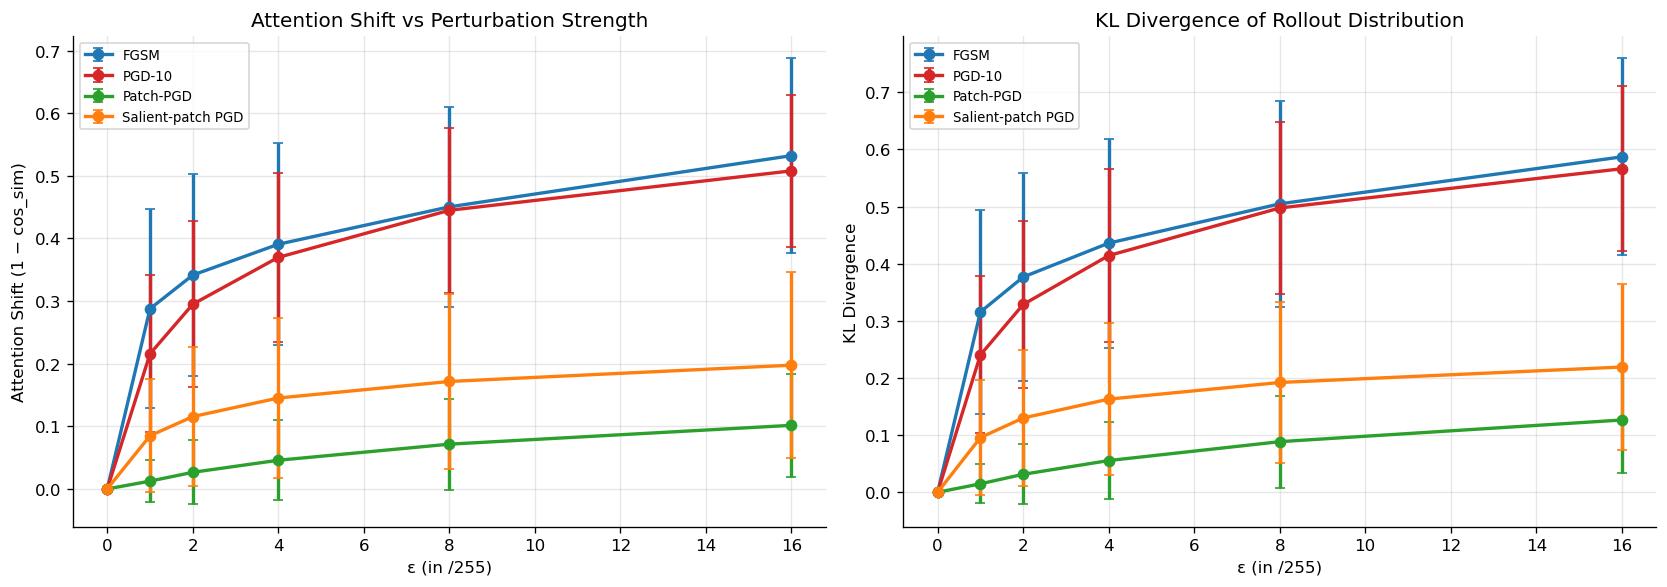

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for atk in attacks:
    sub = attention[attention.attack == atk].sort_values("eps_255")
    c = ATTACK_COLORS[atk]
    lbl = ATTACK_LABELS[atk]

    ax1.errorbar(sub.eps_255, sub.attention_shift, yerr=sub.std_cos_sim,
                 marker="o", lw=2, color=c, label=lbl, capsize=3)
    ax2.errorbar(sub.eps_255, sub.mean_kl_div, yerr=sub.std_kl_div,
                 marker="o", lw=2, color=c, label=lbl, capsize=3)

ax1.set_ylabel("Attention Shift (1 − cos_sim)")
ax1.set_title("Attention Shift vs Perturbation Strength")
ax2.set_ylabel("KL Divergence")
ax2.set_title("KL Divergence of Rollout Distribution")

for ax in (ax1, ax2):
    ax.set_xlabel("ε (in /255)")
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

**Observations:**
- Full-image attacks (FGSM, PGD) produce large attention shifts; FGSM
  actually shifts attention *more* than PGD at equal ε, possibly because
  FGSM perturbs more uniformly across all patches while PGD concentrates
  on the most loss-sensitive directions.
- Spatially constrained attacks (Patch-PGD, Salient-patch PGD) produce
  minimal attention shift, confirming the ViT's attention is robust to
  localised corruption.
- Error bars are substantial, indicating high per-image variability.

---
## 5. Cross-architecture transferability

**What is transferability?**  
An adversarial example is generated by attacking *one* model (the **source**). Transferability asks: if you feed that same perturbed image to a *different* model (the **target**, which was never involved in crafting the attack), does it get fooled too?

**Why does it matter?**  
High transfer means the perturbation exploits a vulnerability shared across architectures — it is attacking something fundamental about how classifiers see the image. Low transfer means the perturbation is *overfitted* to the quirks of the source model's decision boundary and does not generalise.

**The metric — effective transfer rate:**  
We compute the fraction of images that **already fooled the source** model and that also fool the target. Conditioning on source-fooled samples is important: it avoids penalising a transfer pair just because the attack was weak on the source in the first place.

The key question is whether the asymmetry **CNN → ViT** vs **ViT → CNN** is real, and what it tells us about the difference in how the two architecture families process images.


In [13]:
def transfer_matrix(df, attack, eps):
    sub = df[(df.attack == attack) & (df.eps_255 == eps)]
    models = ["vit", "resnet50", "resnet18"]
    labels = ["VB16", "ResNet-50", "ResNet-18"]
    mat = pd.DataFrame(index=labels, columns=labels, dtype=str)
    for _, row in sub.iterrows():
        si = models.index(row.source)
        ti = models.index(row.target)
        mat.iloc[si, ti] = f"{row.effective_transfer:.1%}"
    for i in range(len(models)):
        mat.iloc[i, i] = "—"
    return mat

print("Effective transfer rate — PGD ε=8/255")
print("(of source-fooled samples, what % also fools target?)\n")
display(transfer_matrix(transfer, "pgd", 8))

print("\nEffective transfer rate — FGSM ε=8/255\n")
display(transfer_matrix(transfer, "fgsm", 8))

Effective transfer rate — PGD ε=8/255
(of source-fooled samples, what % also fools target?)



,ViT-Base/16,ResNet-50,ResNet-18
ViT-Base/16,—,6.4%,9.7%
ResNet-50,1.3%,—,25.9%
ResNet-18,1.5%,26.5%,—



Effective transfer rate — FGSM ε=8/255



,ViT-Base/16,ResNet-50,ResNet-18
ViT-Base/16,—,22.2%,30.3%
ResNet-50,4.7%,—,43.1%
ResNet-18,3.1%,25.0%,—


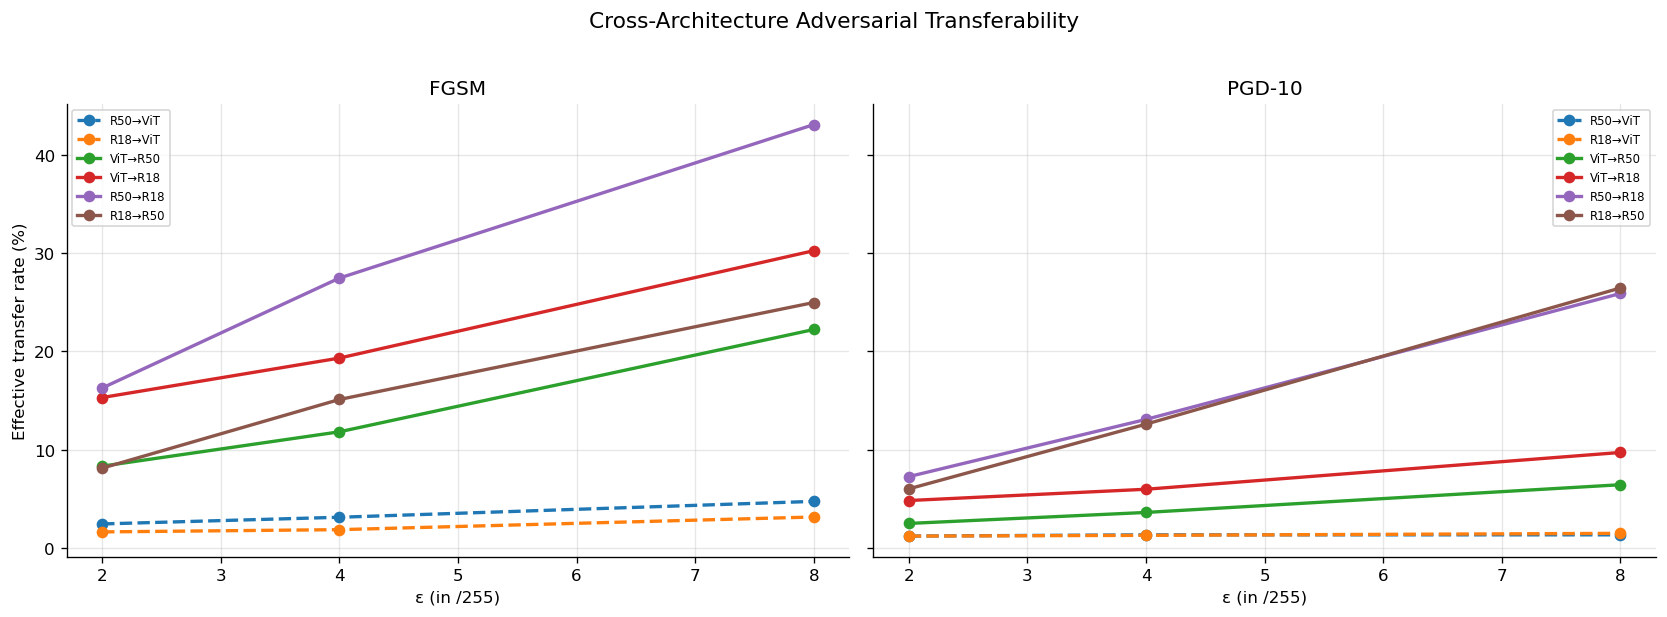

In [14]:
pairs = [("resnet50", "vit"), ("resnet18", "vit"),
         ("vit", "resnet50"), ("vit", "resnet18"),
         ("resnet50", "resnet18"), ("resnet18", "resnet50")]
pair_labels = ["R50→VB16", "R18→VB16", "VB16→R50", "VB16→R18", "R50→R18", "R18→R50"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, atk, title in [(ax1, "fgsm", "FGSM"), (ax2, "pgd", "PGD-10")]:
    sub = transfer[transfer.attack == atk]
    for (src, tgt), lbl in zip(pairs, pair_labels):
        row = sub[(sub.source == src) & (sub.target == tgt)].sort_values("eps_255")
        ls = "--" if "VB16" in lbl.split("→")[1] else "-"
        ax.plot(row.eps_255, row.effective_transfer * 100, marker="o", lw=2, ls=ls, label=lbl)
    ax.set_title(title)
    ax.set_xlabel("ε (in /255)")
    ax.legend(fontsize=7)

ax1.set_ylabel("Effective transfer rate (%)")
fig.suptitle("Cross-Architecture Adversarial Transferability", fontsize=13, y=1.02)
fig.tight_layout()
plt.show()

**Observations:**

- **CNN → ViT transfer is near-zero (1–5 %).** Adversarial perturbations crafted against a CNN exploit *local gradient geometry*: they nudge pixel-level edges and textures that sit along the CNN's loss surface. ViT, by contrast, builds its representation from global patch relationships via self-attention and never looks at the same low-level features in the same way. The CNN-crafted noise is essentially invisible to ViT's inductive bias — the two models are on completely different loss landscapes.

- **CNN → CNN transfer is moderate (26–43 %).** ResNet-50 and ResNet-18 share the same convolutional feature hierarchy and similar decision boundaries, so perturbations generalise within the family.

- **ViT → CNN transfer is low but non-zero (6–30 %, growing with ε).** ViT gradients are spatially diffuse (spread across all patches), which produces perturbations that are less specialised to one model. At large ε the perturbation becomes strong enough to partially cross the architectural gap, hence the upward trend with budget.

- **FGSM transfers better than PGD across all pairs.** PGD iterates many gradient steps, progressively tailoring the perturbation to the *exact* curvature of the source model's loss surface. The result is a highly effective but model-specific adversarial example. FGSM takes a single large step along the dominant gradient direction — a coarser but more *universal* perturbation that is more likely to lie in the adversarial region of other models too.

**Bottom line:** the CNN → ViT near-zero transfer is not just a curiosity — it implies that an adversary who has only managed to attack a CNN-based system cannot automatically exploit a ViT-based one with the same examples. Architectural diversity is a genuine (though not absolute) defence.


---
## 6. Per-class vulnerability

Not all classes degrade equally under attack.

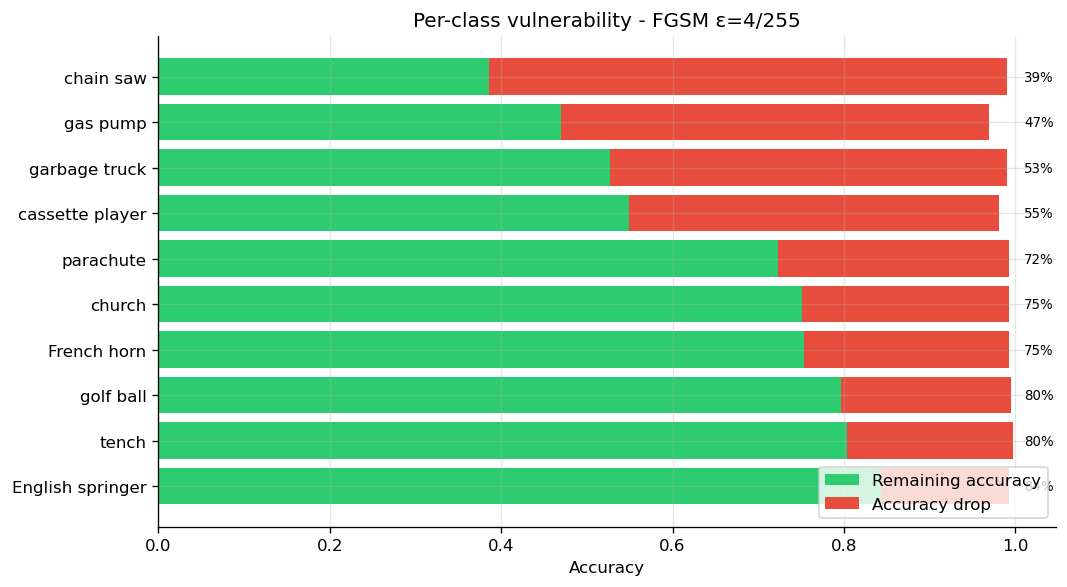

In [17]:
clean_pc = per_class[(per_class.attack == "fgsm") & (per_class.eps_255 == 0)]
adv_pc = per_class[(per_class.attack == "fgsm") & (per_class.eps_255 == 4)]

merged = clean_pc[["class_name", "acc"]].merge(
    adv_pc[["class_name", "acc"]], on="class_name", suffixes=("_clean", "_adv")
)
merged["drop"] = merged.acc_clean - merged.acc_adv
merged = merged.sort_values("drop", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
y_pos = range(len(merged))
ax.barh(y_pos, merged.acc_adv, color="#2ecc71", label="Remaining accuracy")
ax.barh(y_pos, merged["drop"], left=merged.acc_adv, color="#e74c3c", label="Accuracy drop")
ax.set_yticks(y_pos)
ax.set_yticklabels(merged.class_name)
ax.set_xlabel("Accuracy")
ax.set_title("Per-class vulnerability - FGSM ε=4/255")
ax.legend(loc="lower right")

for i, row in enumerate(merged.itertuples()):
    ax.text(1.01, i, f"{row.acc_adv:.0%}", va="center", fontsize=8)

fig.tight_layout()
plt.show()

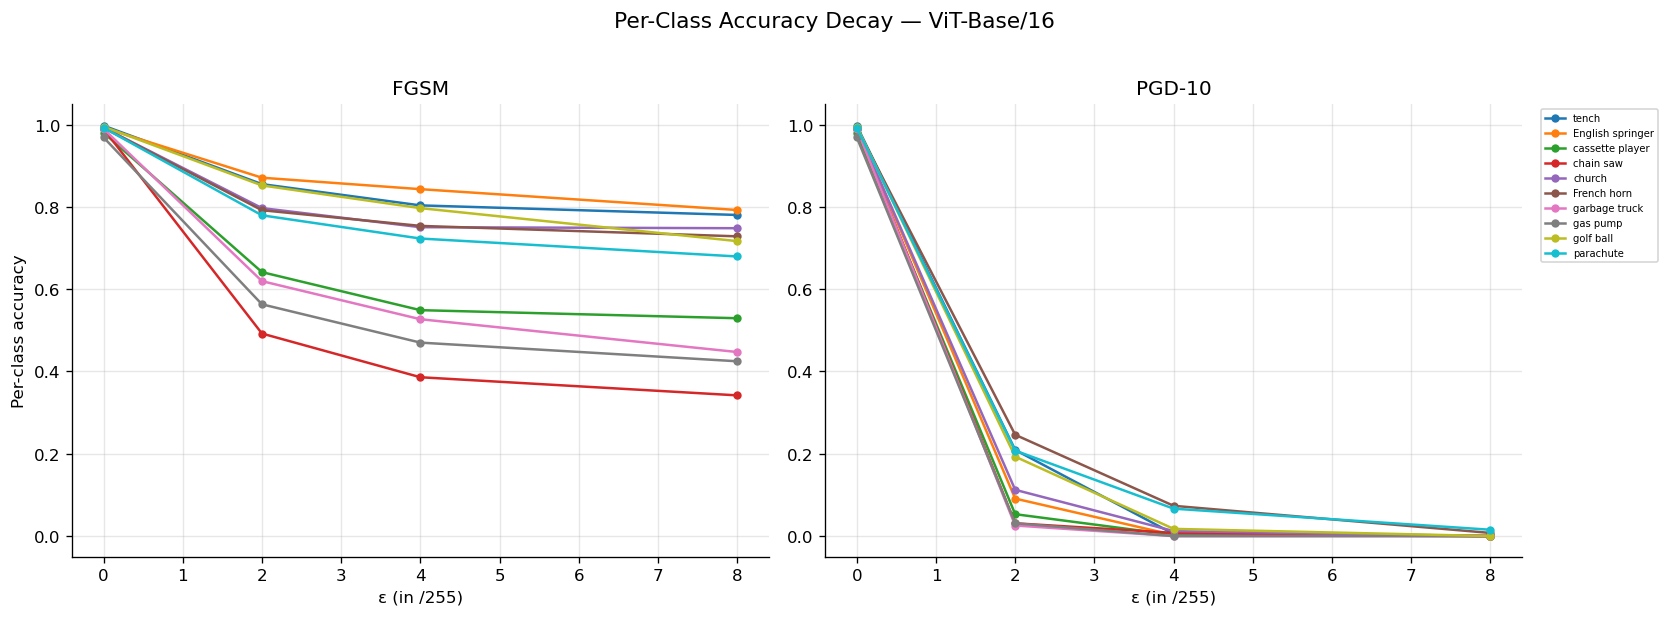

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, atk in zip(axes, ["fgsm", "pgd"]):
    sub = per_class[per_class.attack == atk]
    for cls in sub.class_name.unique():
        cls_data = sub[sub.class_name == cls].sort_values("eps_255")
        ax.plot(cls_data.eps_255, cls_data.acc, marker="o", lw=1.5, markersize=4, label=cls)
    ax.set_title(ATTACK_LABELS[atk])
    ax.set_xlabel("ε (in /255)")
    ax.set_ylim(-0.05, 1.05)

axes[0].set_ylabel("Per-class accuracy")
axes[-1].legend(fontsize=6, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Per-Class Accuracy Decay — VB16", fontsize=13, y=1.02)
fig.tight_layout()
plt.show()

**Observations:**
- *Chain saw*, *gas pump*, and *garbage truck* are the most vulnerable:
  these share localised, high-frequency discriminative features (blade
  texture, uniform colours, geometric structure) that are easily
  disrupted by L∞ perturbations.
- *English springer*, *tench*, and *golf ball* are the most robust under FGSM:
  their discriminative features are distributed and redundant (body shape,
  fin patterns, uniform surface texture).
- Under PGD ε≥4, all classes collapse to ~0%, erasing the per-class
  structure visible under FGSM.

---
## 7. Summary

| Finding | Evidence |
|---|---|
| ViT degrades more gracefully than CNNs under FGSM | AUDC: ViT 0.635 vs R50 0.530 vs R18 0.317 |
| Under PGD, ViT buys time but eventually collapses | ViT holds 41% at ε=1/255 where CNNs are already at 0% |
| Attacks redirect ViT attention to background | Attention shift (1−cos_sim) reaches 0.53 at ε=16/255 |
| Cross-architecture transfer is near-zero | CNN→ViT effective transfer: 1.3% (PGD ε=8/255) |
| Per-class vulnerability varies 4x | 60pp drop for chain saw vs 15pp for English springer (FGSM ε=4) |
| All models become catastophically overconfident under PGD | conf_wrong → 1.0 even at accuracy ≈ 0% |